In [162]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

STUDENT_ID = 20244080202
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] pyhomework
[学号]       20244080202
[机器指纹] 0d25ba29a288e7c8
[RUN_ID]   20244080202-0d25ba29a288e7c8


In [163]:
#实验1：NumPy 数组、数据类型与索引
arr_int = np.array([1, 2, 3, 4])
arr_float = np.array([1.2, 2.5, 3.8])
arr_bool = np.array([True, False, True])

for name, arr in [("整数数组", arr_int), ("浮点数组", arr_float), ("布尔数组", arr_bool)]:
    print(f"{name}: {arr}")
    print(f"dtype={arr.dtype}, shape={arr.shape}, ndim={arr.ndim}\n")


整数数组: [1 2 3 4]
dtype=int64, shape=(4,), ndim=1

浮点数组: [1.2 2.5 3.8]
dtype=float64, shape=(3,), ndim=1

布尔数组: [ True False  True]
dtype=bool, shape=(3,), ndim=1



In [164]:
arr = np.arange(12)
arr_34 = arr.reshape(3, 4)
arr_232 = arr.reshape(2, 3, 2)
print("一维数组：", arr)
print("形状 (3, 4)：\n", arr_34)
print("形状 (2, 3, 2)：\n", arr_232)
print("说明：reshape 前后元素总数必须相同，此处均为 12。")


一维数组： [ 0  1  2  3  4  5  6  7  8  9 10 11]
形状 (3, 4)：
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
形状 (2, 3, 2)：
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
说明：reshape 前后元素总数必须相同，此处均为 12。


In [165]:
print("第2行：", arr_34[1], "shape =", arr_34[1].shape)
print("第1至第3列（按题目列序号理解为第1、2、3列）：\n", arr_34[:, 0:3],
      "shape =", arr_34[:, 0:3].shape)
greater6 = arr_34[arr_34 > 6]
print("大于6的元素：", greater6, "shape =", greater6.shape)

第2行： [4 5 6 7] shape = (4,)
第1至第3列（按题目列序号理解为第1、2、3列）：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape = (3, 3)
大于6的元素： [ 7  8  9 10 11] shape = (5,)


In [166]:
arr10 = np.arange(10)
print("小于2或大于7：", arr10[(arr10 < 2) | (arr10 > 7)])
print("大于3且小于7：", arr10[(arr10 > 3) & (arr10 < 7)])

小于2或大于7： [0 1 8 9]
大于3且小于7： [4 5 6]


In [167]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print("A * B（逐元素乘法）：\n", A * B)
print("np.multiply(A, B)：\n", np.multiply(A, B))
print("A @ B（矩阵乘法）：\n", A @ B)
print("np.matmul(A, B)：\n", np.matmul(A, B))
print("说明：* 和 multiply 对对应位置元素相乘；@ 和 matmul 按矩阵乘法规则计算。")

A * B（逐元素乘法）：
 [[ 5 12]
 [21 32]]
np.multiply(A, B)：
 [[ 5 12]
 [21 32]]
A @ B（矩阵乘法）：
 [[19 22]
 [43 50]]
np.matmul(A, B)：
 [[19 22]
 [43 50]]
说明：* 和 multiply 对对应位置元素相乘；@ 和 matmul 按矩阵乘法规则计算。


In [168]:
#实验2：随机抽样、统计与缺失值
rng = np.random.default_rng(42)
scores = np.clip(rng.normal(loc=70, scale=10, size=1000), 0, 100)
print("样本数：", scores.size)
print("最小值：", scores.min())
print("最大值：", scores.max())
print("均值：", scores.mean())
print("标准差：", scores.std())
print("极差：", np.ptp(scores))

样本数： 1000
最小值： 33.51587174785217
最大值： 100.0
均值： 69.70929595324685
标准差： 9.881580939490172
极差： 66.48412825214783


In [169]:
numbers = np.arange(1, 11)
uniform_sample = rng.choice(numbers, size=5, replace=False)
weights = numbers / numbers.sum()
weighted_sample = rng.choice(numbers, size=5, replace=False, p=weights)
print("原数组：", numbers)
print("均匀不放回抽样：", uniform_sample)
print("按数值大小加权的不放回抽样：", weighted_sample)
print("加权概率：", weights)
print("说明：加权抽样中，数值越大，被抽中的概率越高；两种方式均不重复抽取。")

原数组： [ 1  2  3  4  5  6  7  8  9 10]
均匀不放回抽样： [7 2 9 5 4]
按数值大小加权的不放回抽样： [3 9 2 6 5]
加权概率： [0.01818182 0.03636364 0.05454545 0.07272727 0.09090909 0.10909091
 0.12727273 0.14545455 0.16363636 0.18181818]
说明：加权抽样中，数值越大，被抽中的概率越高；两种方式均不重复抽取。


In [170]:
original = np.arange(1, 11)
permuted = rng.permutation(original)
print("原数组（操作前）：", original)
print("permutation 返回的新数组：", permuted)
print("原数组（permutation 后仍不变）：", original)

inplace_array = original.copy()
print("原地打乱前：", inplace_array)
rng.shuffle(inplace_array)
print("原地打乱后：", inplace_array)
print("说明：permutation 返回排列后的新数组；shuffle 直接修改传入数组。")

原数组（操作前）： [ 1  2  3  4  5  6  7  8  9 10]
permutation 返回的新数组： [ 2 10  3  5  1  9  7  8  4  6]
原数组（permutation 后仍不变）： [ 1  2  3  4  5  6  7  8  9 10]
原地打乱前： [ 1  2  3  4  5  6  7  8  9 10]
原地打乱后： [ 1  2 10  3  6  8  9  4  5  7]
说明：permutation 返回排列后的新数组；shuffle 直接修改传入数组。


In [171]:
scores_missing = scores.copy()
scores_missing[[9, 19, 29]] = np.nan
print("普通均值：", np.mean(scores_missing))
print("忽略缺失值的均值：", np.nanmean(scores_missing))
print("缺失值个数：", np.isnan(scores_missing).sum())
print("说明：普通 mean 遇到 NaN 通常会返回 NaN；nanmean 会忽略 NaN。")

普通均值： nan
忽略缺失值的均值： 69.71315691233939
缺失值个数： 3
说明：普通 mean 遇到 NaN 通常会返回 NaN；nanmean 会忽略 NaN。


In [172]:
score_table = pd.DataFrame({
    "序号": np.arange(1, len(scores_missing) + 1),
    "成绩": scores_missing
})
print(score_table.head(10))
print("表格形状：", score_table.shape)
print("此表仅保存在内存中，没有写入磁盘。")

   序号         成绩
0   1  73.047171
1   2  59.600159
2   3  77.504512
3   4  79.405647
4   5  50.489648
5   6  56.978205
6   7  71.278404
7   8  66.837574
8   9  69.831988
9  10        NaN
表格形状： (1000, 2)
此表仅保存在内存中，没有写入磁盘。


In [173]:
#实验3：SciPy 数值计算与 Matplotlib 可视化

import numpy as np
from scipy import linalg

coefficients = np.array([[3, 1], [1, 2]], dtype=float)
constants = np.array([9, 8], dtype=float)

solution = linalg.solve(coefficients, constants)

print("解 [x, y]：", solution)
print("NumPy 代入验证结果：", coefficients @ solution)
print("原方程右侧：", constants)

解 [x, y]： [2. 3.]
NumPy 代入验证结果： [9. 8.]
原方程右侧： [9. 8.]


In [174]:

from scipy import optimize

def equation(x):
    return x**2 - 2

positive_root = optimize.root(equation, x0=1.0)
negative_root = optimize.root(equation, x0=-1.0)

for label, result in [("正根", positive_root), ("负根", negative_root)]:
    print(f"{label}求根是否成功：", result.success)
    print(f"{label}：", result.x)
    print(f"函数值：", equation(result.x))
    print()


正根求根是否成功： True
正根： [1.41421356]
函数值： [-8.8817842e-16]

负根求根是否成功： True
负根： [-1.41421356]
函数值： [-8.8817842e-16]



In [175]:
def objective(x):
    return x[0]**2 + x[0] + 2

minimum = optimize.minimize(objective, x0=np.array([0.0]))
print("数值优化成功：", minimum.success)
print("数值极小点 x：", minimum.x[0])
print("数值最小值 f(x)：", minimum.fun)
print("解析结果：x=-0.5，最小值=1.75")
print("说明：配方 f(x)=(x+0.5)^2+1.75，因此解析极小点为 -0.5。")

数值优化成功： True
数值极小点 x： -0.5000000064345924
数值最小值 f(x)： 1.75
解析结果：x=-0.5，最小值=1.75
说明：配方 f(x)=(x+0.5)^2+1.75，因此解析极小点为 -0.5。


In [176]:

from scipy import stats

sample1 = rng_test.normal(loc=0, scale=1, size=100)
sample2 = rng_test.normal(loc=1, scale=1, size=100)

t_result = stats.ttest_ind(sample1, sample2, equal_var=True)

print("t统计量：", t_result.statistic)
print("p值：", t_result.pvalue)

if t_result.pvalue < 0.05:
    print("判断：在 0.05 显著性水平下，两组样本均值存在显著差异。")
else:
    print("判断：在 0.05 显著性水平下，没有足够证据认为两组样本均值存在显著差异。")


t统计量： -5.873414883100056
p值： 1.7792207359088863e-08
判断：在 0.05 显著性水平下，两组样本均值存在显著差异。


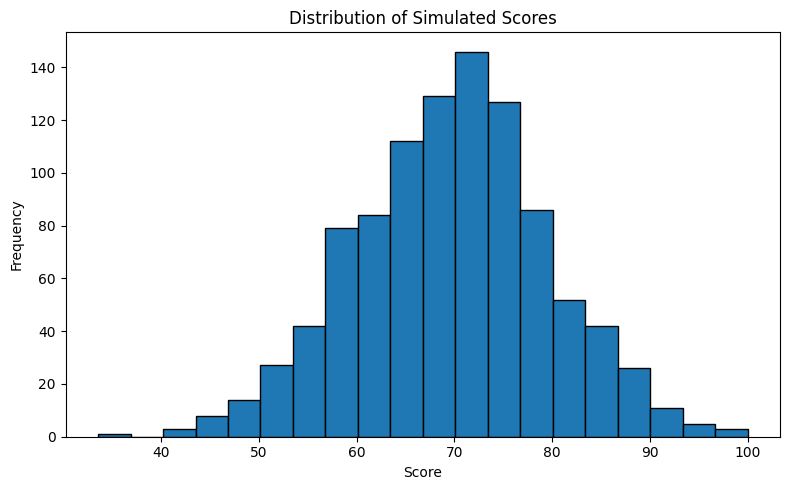

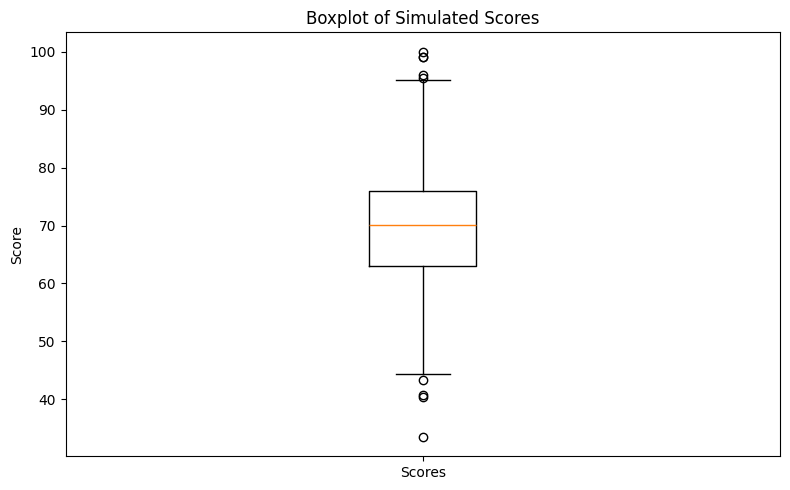

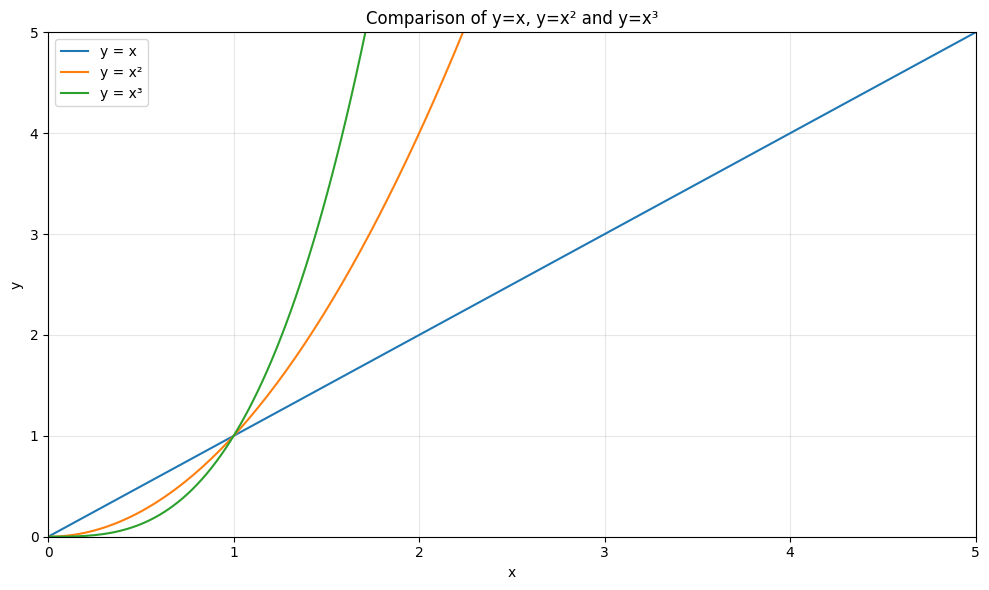

In [177]:

import numpy as np
import matplotlib.pyplot as plt

valid_scores = scores_missing[~np.isnan(scores_missing)]

plt.figure(figsize=(8, 5))
plt.hist(valid_scores, bins=20, edgecolor="black")
plt.title("Distribution of Simulated Scores")
plt.xlabel("Score")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.boxplot(valid_scores, tick_labels=["Scores"])
plt.title("Boxplot of Simulated Scores")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

x = np.linspace(0, 5, 200)

plt.figure(figsize=(10, 6))
plt.plot(x, x, label="y = x")
plt.plot(x, x**2, label="y = x²")
plt.plot(x, x**3, label="y = x³")

plt.title("Comparison of y=x, y=x² and y=x³")
plt.xlabel("x")
plt.ylabel("y")
plt.xlim(0, 5)
plt.ylim(0, 5) 
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [178]:
#pandas Series、DataFrame 与内存中的 CSV 读写
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")
score_columns = ["Math", "English", "Python"]
df["Total"] = df[score_columns].sum(axis=1)
df["Average"] = df[score_columns].mean(axis=1)
print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前3行：\n", df.head(3))
print("\n基本统计信息：\n", df.describe())

行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行：
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计信息：
             Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000


In [179]:
print("loc 读取 Carol：\n", df.loc["Carol"])
carol_position = df.index.get_loc("Carol")
print("iloc 读取 Carol：\n", df.iloc[carol_position])
print("平均分不低于80的学生：\n", df[df["Average"] >= 80])

loc 读取 Carol：
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
iloc 读取 Carol：
 Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object
平均分不低于80的学生：
       Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Carol     B    91       85      89    265  88.333333
Eva       A    79       92      86    257  85.666667
Frank     B    84       77      82    243  81.000000


In [180]:
print("三科列均值（mean(axis=0)）：\n", df[score_columns].mean(axis=0))
print("每名学生行均值（mean(axis=1)）：\n", df[score_columns].mean(axis=1))
print("与 Average 列核对：\n", df["Average"])

三科列均值（mean(axis=0)）：
 Math       79.833333
English    80.833333
Python     83.666667
dtype: float64
每名学生行均值（mean(axis=1)）：
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64
与 Average 列核对：
 Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
Name: Average, dtype: float64


In [181]:
df["Highest"] = df[score_columns].apply(max, axis=1)
print("每名学生三科最高分：\n", df["Highest"])
print("每科最小值、均值、最大值：\n", df[score_columns].agg(["min", "mean", "max"]))
df["MathRank"] = df["Math"].rank(ascending=False, method="min").astype(int)
print("按数学成绩排名：\n", df[["Math", "MathRank"]].sort_values("MathRank"))

每名学生三科最高分：
 Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
Name: Highest, dtype: int64
每科最小值、均值、最大值：
            Math    English     Python
min   65.000000  68.000000  70.000000
mean  79.833333  80.833333  83.666667
max   91.000000  92.000000  95.000000
按数学成绩排名：
        Math  MathRank
Name                 
Carol    91         1
Alice    88         2
Frank    84         3
Eva      79         4
Bob      72         5
David    65         6


In [182]:
group_summary = df.groupby("Group").agg(
    人数=("Python", "size"),
    数学平均分=("Math", "mean"),
    英语平均分=("English", "mean"),
    Python平均分=("Python", "mean")
)
df["GroupPythonMean"] = df.groupby("Group")["Python"].transform("mean")
print("分组统计：\n", group_summary)
print("每名学生所在组的 Python 平均分：\n", df[["Group", "Python", "GroupPythonMean"]])

分组统计：
        人数      数学平均分      英语平均分  Python平均分
Group                                     
A       3  79.666667  83.333333  87.000000
B       3  80.000000  78.333333  80.333333
每名学生所在组的 Python 平均分：
       Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333


In [183]:
kept_groups = df.groupby("Group").filter(lambda group: group["Python"].mean() >= 80)
print("保留的学生及所在组：\n", kept_groups[["Group", "Python", "GroupPythonMean"]])
print("保留的组：", kept_groups["Group"].unique().tolist())

保留的学生及所在组：
       Group  Python  GroupPythonMean
Name                                
Alice     A      95        87.000000
Bob       A      80        87.000000
Carol     B      89        80.333333
David     B      70        80.333333
Eva       A      86        87.000000
Frank     B      82        80.333333
保留的组： ['A', 'B']


In [184]:
print("三科协方差矩阵：\n", df[score_columns].cov())
print("三科皮尔森相关系数矩阵：\n", df[score_columns].corr())
cov_value = df["Math"].cov(df["English"])
corr_value = df["Math"].corr(df["English"])
print(f"数学与英语的协方差：{cov_value:.4f}")
print(f"数学与英语的相关系数：{corr_value:.4f}")
print("解释：协方差为正表示两科成绩倾向于同向变化；相关系数在 -1 到 1 之间，绝对值越接近 1，线性相关越强，接近 0 表示线性相关较弱。")

三科协方差矩阵：
               Math    English     Python
Math     98.166667  62.566667  74.933333
English  62.566667  93.366667  62.533333
Python   74.933333  62.533333  73.066667
三科皮尔森相关系数矩阵：
              Math   English    Python
Math     1.000000  0.653529  0.884776
English  0.653529  1.000000  0.757105
Python   0.884776  0.757105  1.000000
数学与英语的协方差：62.5667
数学与英语的相关系数：0.6535
解释：协方差为正表示两科成绩倾向于同向变化；相关系数在 -1 到 1 之间，绝对值越接近 1，线性相关越强，接近 0 表示线性相关较弱。


In [185]:
csv_text = df.reset_index().to_csv(index=False)
df_from_csv = pd.read_csv(__import__("io").StringIO(csv_text))
print("CSV 文本前几行：")
print("\n".join(csv_text.splitlines()[:4]))
print("从内存 CSV 文本读取后的数据前3行：\n", df_from_csv.head(3))

CSV 文本前几行：
Name,Group,Math,English,Python,Total,Average,Highest,MathRank,GroupPythonMean
Alice,A,88,90,95,273,91.0,95,2,87.0
Bob,A,72,68,80,220,73.33333333333333,80,5,87.0
Carol,B,91,85,89,265,88.33333333333333,91,1,80.33333333333333
从内存 CSV 文本读取后的数据前3行：
     Name Group  Math  English  Python  Total    Average  Highest  MathRank  \
0  Alice     A    88       90      95    273  91.000000       95         2   
1    Bob     A    72       68      80    220  73.333333       80         5   
2  Carol     B    91       85      89    265  88.333333       91         1   

   GroupPythonMean  
0        87.000000  
1        87.000000  
2        80.333333  
